# BERT Fine-tune

In [1]:
from functools import partial
from pathlib import Path

import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from bert_data import BertReviewDataset, collate_bert_reviews
from utils import get_device
from train import train_model
from utils import plot_history


c:\Users\99243\miniconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Pre-Trained Model

In [2]:
MODEL_NAME = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


## Dataloader

In [3]:
DATA_DIR = "data/merged"
GENRE = "FPS"
batch_size = 64

torch.manual_seed(42)

data_dir = Path(DATA_DIR)

collate_fn = partial(
    collate_bert_reviews,
    tokenizer=tokenizer,
    max_length=256
)

loaders = {}

for split in ("train", "val", "test"):
    df = pd.read_csv(
        data_dir / f"{GENRE}_{split}.csv",
        dtype={"review": "string", "voted_up": "int64"},
    )

    loaders[split] = DataLoader(
        BertReviewDataset(df),
        batch_size=batch_size,
        shuffle=(split == "train"),
        collate_fn=collate_fn,
        num_workers=0,
        generator=(
            torch.Generator().manual_seed(42)
            if split == "train" else None
        ),
    )

train_set = loaders["train"]
val_set = loaders["val"]
test_set = loaders["test"]

## BERT Classifier Model

In [4]:
class BertClassifier(nn.Module):
    """Return sentiment logits from a pretrained BERT classifier."""

    def __init__(self, model_name):
        super().__init__()

        self.bert = AutoModelForSequenceClassification.from_pretrained(
            model_name,
            num_labels=2,
            id2label={0: "not recommended", 1: "recommended"},
            label2id={"not recommended": 0, "recommended": 1},
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        return outputs.logits

## Training

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2412.87it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

Training on: cuda(NVIDIA GeForce RTX 5070 Ti)
Average speed: 8337 tokens/sec
Train loss: 0.073 | Train accuracy: 0.976 | Val accuracy: 0.876


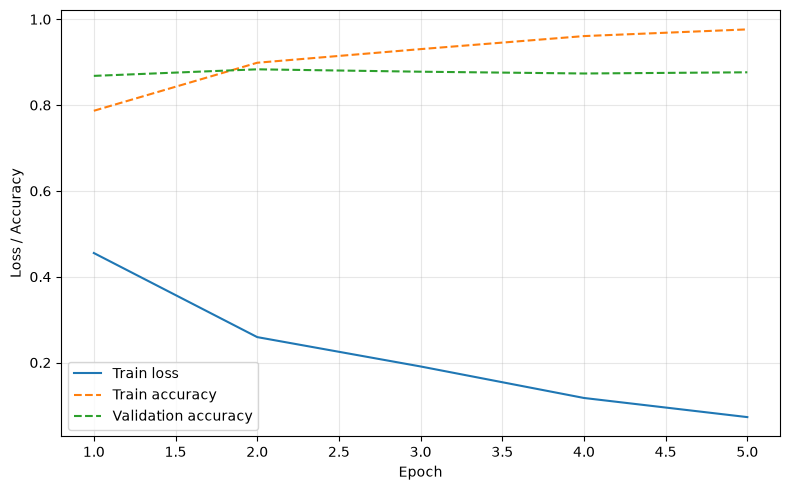

In [5]:
num_epochs, lr = 5, 2e-5

device = get_device()
net = BertClassifier(MODEL_NAME).to(device)

loss = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    net.parameters(),
    lr=lr,
)

# Reuse one figure and update its notebook output after each epoch.
with plt.ioff():
    fig, ax = plt.subplots(figsize=(8, 5))
plot_display = display(fig, display_id=True)
plt.close(fig)  # Avoid an extra automatic inline display.

def update_training_plot(history):
    plot_history(history, ax=ax)
    plot_display.update(fig)

metric_history = train_model(
    model=net,
    train_loader=train_set,
    val_loader=val_set,
    loss_fn=loss,
    optimizer=optimizer,
    num_epochs=num_epochs,
    device=device,
    on_epoch_end=update_training_plot,
)

last_metrics = metric_history[-1]
print(
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}"
)